# Swin UNETR 特征尺寸

升级 MONAI，用随机 3D 输入前向一次，展示 Swin 五个尺度、编码器和解码器的输出尺寸。

In [1]:
%pip install -q --upgrade monai
%pip install -q einops matplotlib pandas

In [2]:
import torch
import monai
import pandas as pd
import matplotlib.pyplot as plt
from monai.networks.nets import SwinUNETR

# CPU 上可改为 (64, 64, 64) 和 feature_size=24。
input_size = (96, 96, 96)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SwinUNETR(
    in_channels=1, out_channels=14, feature_size=48, spatial_dims=3,
).to(device).eval()
x = torch.randn(1, 1, *input_size, device=device)
shapes = {"input": tuple(x.shape)}

# 记录主要网络层；swinViT 的列表输出包含五个尺度。
def record_shape(name):
    def hook(module, inputs, output):
        outputs = output if isinstance(output, (list, tuple)) else [output]
        for i, tensor in enumerate(outputs):
            label = f"{name}[{i}]" if len(outputs) > 1 else name
            shapes[label] = tuple(tensor.shape)
    return hook

hooks = [layer.register_forward_hook(record_shape(name))
         for name, layer in model.named_children()]
try:
    with torch.inference_mode():
        y = model(x)
finally:
    for hook in hooks:
        hook.remove()

print(f"MONAI {monai.__version__} | {device}")
print(f"Input: {tuple(x.shape)} → Output: {tuple(y.shape)}")

MONAI 1.6.1 | cuda
Input: (1, 1, 96, 96, 96) → Output: (1, 14, 96, 96, 96)


,Layer,"Shape (B, C, D, H, W)"
0,input,"(1, 1, 96, 96, 96)"
1,swinViT[0],"(1, 48, 48, 48, 48)"
2,swinViT[1],"(1, 96, 24, 24, 24)"
3,swinViT[2],"(1, 192, 12, 12, 12)"
4,swinViT[3],"(1, 384, 6, 6, 6)"
5,swinViT[4],"(1, 768, 3, 3, 3)"
6,encoder1,"(1, 48, 96, 96, 96)"
7,encoder2,"(1, 48, 48, 48, 48)"
8,encoder3,"(1, 96, 24, 24, 24)"
9,encoder4,"(1, 192, 12, 12, 12)"


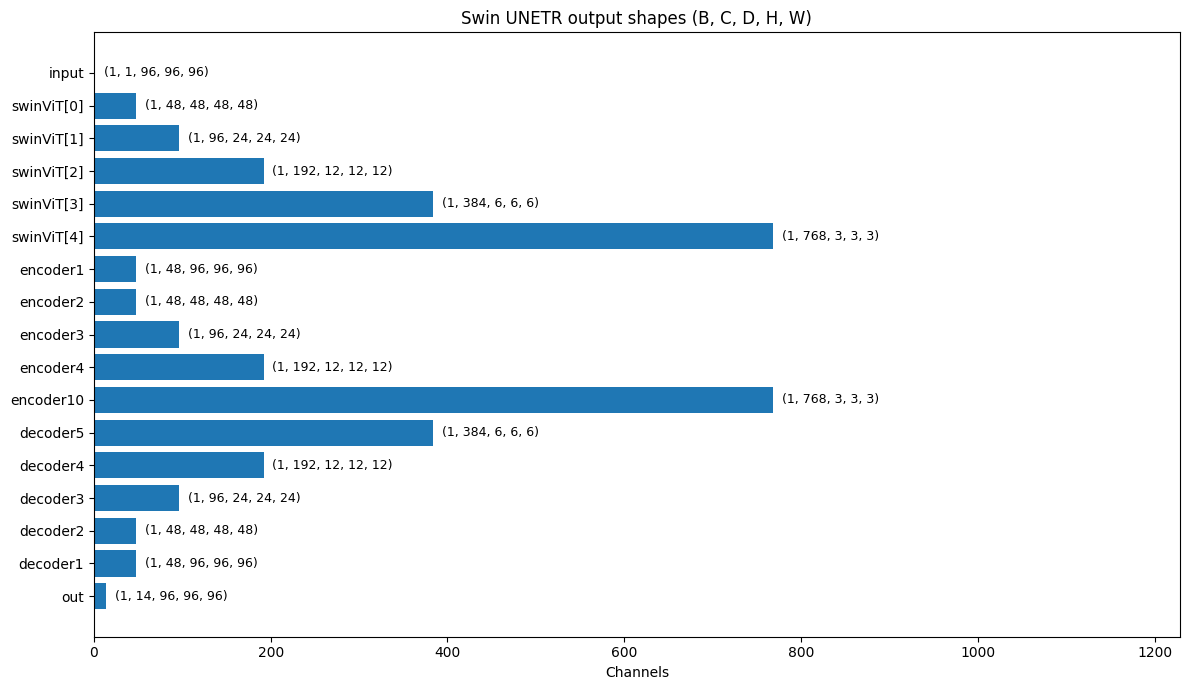

In [3]:
from IPython.display import display

display(pd.DataFrame(shapes.items(), columns=["Layer", "Shape (B, C, D, H, W)"]))

# 横条显示通道数，右侧标注完整输出尺寸。
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(list(shapes), [shape[1] for shape in shapes.values()])
for i, shape in enumerate(shapes.values()):
    ax.text(shape[1] + 10, i, str(shape), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, max(shape[1] for shape in shapes.values()) * 1.6)
ax.set_xlabel("Channels")
ax.set_title("Swin UNETR output shapes (B, C, D, H, W)")
plt.tight_layout()
plt.show()

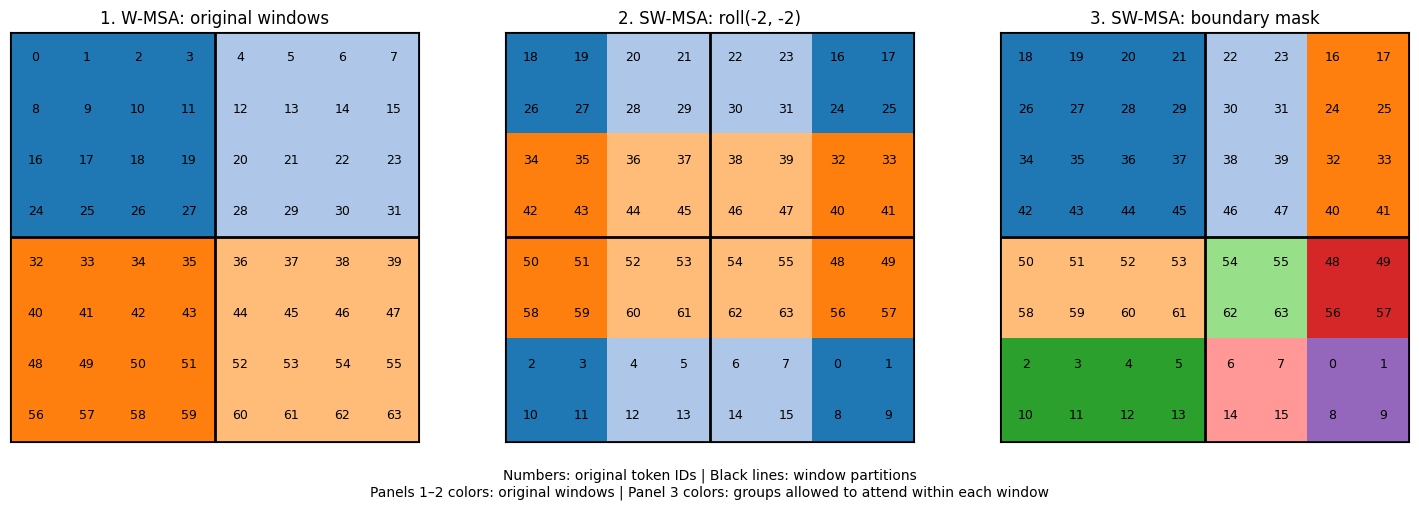

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 二维示意：8×8 tokens，window=4，shift=2；3D 对三个空间轴做同样操作。
n, window, shift = 8, 4, 2
tokens = np.arange(n * n).reshape(n, n)
r, c = np.indices((n, n))
windows = (r // window) * (n // window) + c // window
shifted = np.roll(tokens, (-shift, -shift), axis=(0, 1))
shifted_colors = np.roll(windows, (-shift, -shift), axis=(0, 1))

# 标记循环移位引入的边界区域，同一窗口内不同区域之间禁止 attention。
regions = np.zeros((n, n), dtype=int)
slices = (slice(0, -window), slice(-window, -shift), slice(-shift, None))
for i, rows in enumerate(slices):
    for j, cols in enumerate(slices):
        regions[rows, cols] = i * 3 + j
_, groups = np.unique(windows * 9 + regions, return_inverse=True)
groups = groups.reshape(n, n)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, colors, ids, title in zip(
    axes, [windows, shifted_colors, groups], [tokens, shifted, shifted],
    ["1. W-MSA: original windows", "2. SW-MSA: roll(-2, -2)", "3. SW-MSA: boundary mask"],
):
    ax.imshow(colors, cmap="tab20", vmin=0, vmax=19)
    for row in range(n):
        for col in range(n):
            ax.text(col, row, str(ids[row, col]), ha="center", va="center", fontsize=9)
    for edge in np.arange(-0.5, n, window):
        ax.axhline(edge, color="black", linewidth=2)
        ax.axvline(edge, color="black", linewidth=2)
    ax.set(title=title, xticks=[], yticks=[])
fig.text(0.5, 0.04,
         "Numbers: original token IDs | Black lines: window partitions\n"
         "Panels 1–2 colors: original windows | Panel 3 colors: groups allowed to attend within each window",
         ha="center", fontsize=10)
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()